# Práctica 4 — Tarea 1: Detección y seguimiento de vehículos, personas y matrículas

Instalaciones previas

In [ ]:
#%pip install ultralytics lap

Paquetes necesarios

In [1]:
import os
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

CONFIGURACIÓN (rutas y parámetros)

In [13]:
# Rutas (relativas a la carpeta TAREAS/)
VIDEO_PATH        = '../videos/C0142.mp4'
DATASET_YAML      = '../dataset/data.yaml'
MODELO_GENERAL    = '../modelos/yolo11n.pt'
MODELO_MATRICULAS = 'runs/modelos/runs/matriculas/weights/best.pt'

# Salidas
CARPETA_RESULTADOS = '../resultados'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
SALIDA_VIDEO = os.path.join(CARPETA_RESULTADOS, 'resultado.mp4')
SALIDA_CSV   = os.path.join(CARPETA_RESULTADOS, 'resultado.csv')

# Clases COCO de interés (persona y vehículos)
CLASES_INTERES = {0: 'persona', 1: 'bicicleta', 2: 'coche', 3: 'moto', 5: 'autobus', 7: 'camion'}

---
# PARTE 1: DETECTOR DE MATRÍCULAS

PASO 1.1: REVISAR EL DATASET (estructura train/val/test, imágenes y labels)

El dataset se ha preparado con `dataset/preparar_dataset.py`: se unieron todas las imágenes y anotaciones,
se repartieron 64/16/20 en train/val/test (sin repetir matrícula entre splits) y se convirtieron las anotaciones JSON a formato YOLO.

train:  1527 imágenes |  1527 labels |  3294 matrículas
val  :   382 imágenes |   382 labels |   862 matrículas
test :   478 imágenes |   478 labels |  1079 matrículas


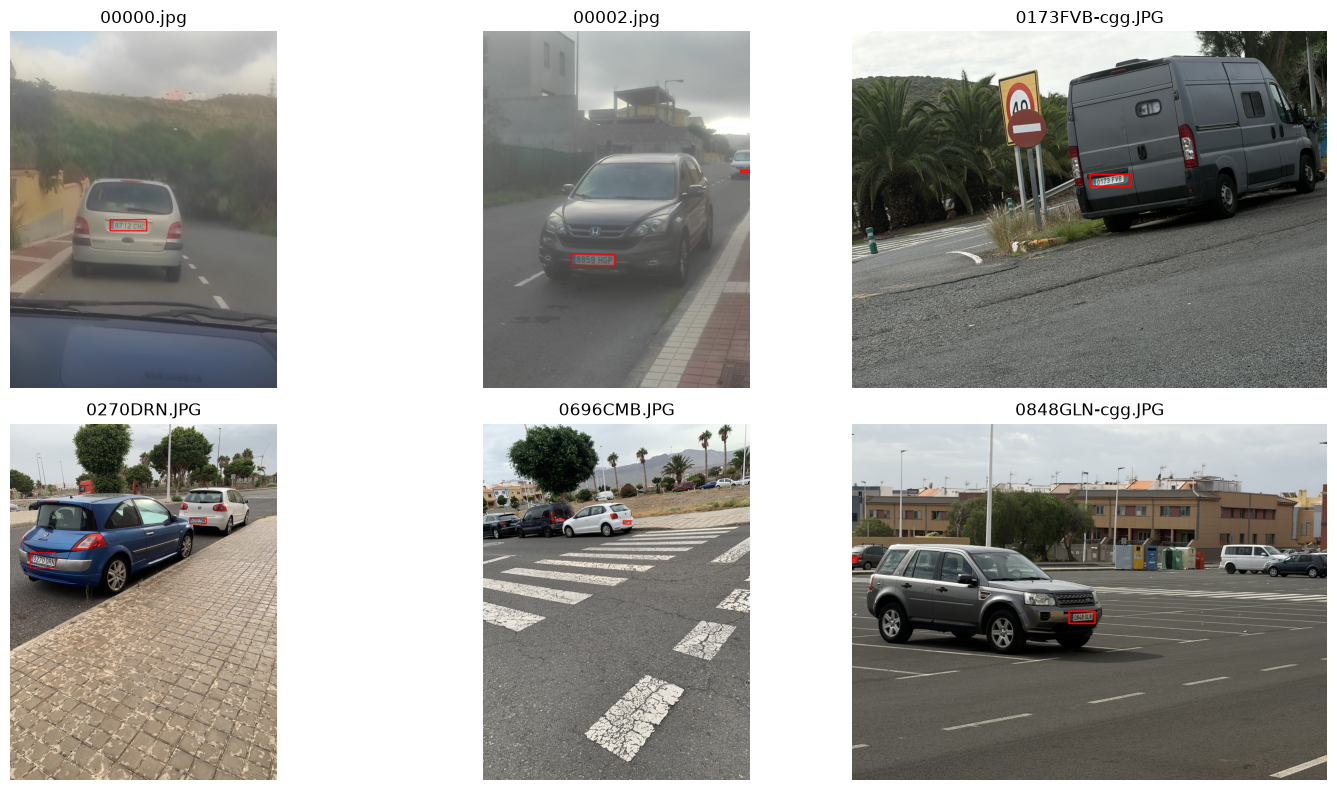

In [3]:
DATASET_DIR = os.path.dirname(DATASET_YAML)

# Resumen por split
for split in ['train', 'val', 'test']:
    imgs   = os.listdir(os.path.join(DATASET_DIR, split, 'images'))
    labels = os.listdir(os.path.join(DATASET_DIR, split, 'labels'))
    n_cajas = 0
    for l in labels:
        with open(os.path.join(DATASET_DIR, split, 'labels', l)) as f:
            n_cajas += sum(1 for linea in f if linea.strip())
    print(f'{split:5s}: {len(imgs):5d} imágenes | {len(labels):5d} labels | {n_cajas:5d} matrículas')

# Ejemplos con sus cajas
split = 'train'
nombres = sorted(os.listdir(os.path.join(DATASET_DIR, split, 'images')))[:6]
plt.figure(figsize=(15, 8))
for i, nombre in enumerate(nombres):
    img = cv2.imread(os.path.join(DATASET_DIR, split, 'images', nombre))
    h, w = img.shape[:2]
    with open(os.path.join(DATASET_DIR, split, 'labels', os.path.splitext(nombre)[0] + '.txt')) as f:
        for linea in f:
            _, cx, cy, bw, bh = map(float, linea.split())
            x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
            x2, y2 = int((cx + bw/2) * w), int((cy + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), max(2, w // 300))
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(nombre)
    plt.axis('off')
plt.tight_layout()
plt.show()

PASO 1.2: ARCHIVO data.yaml

In [4]:
import yaml

with open(DATASET_YAML, encoding='utf-8') as f:
    config = yaml.safe_load(f)
print(yaml.dump(config, allow_unicode=True))

# Comprobar que las rutas existen
for split in ['train', 'val', 'test']:
    ruta = os.path.join(config['path'], config[split])
    print(f'{split:5s} -> {ruta}  {"OK" if os.path.isdir(ruta) else "NO EXISTE"}')

names:
- matricula
nc: 1
path: C:/Users/Usuario/Desktop/escitorio2/VC/VC/PRACTICA_4/dataset
test: test/images
train: train/images
val: val/images

train -> C:/Users/Usuario/Desktop/escitorio2/VC/VC/PRACTICA_4/dataset\train/images  OK
val   -> C:/Users/Usuario/Desktop/escitorio2/VC/VC/PRACTICA_4/dataset\val/images  OK
test  -> C:/Users/Usuario/Desktop/escitorio2/VC/VC/PRACTICA_4/dataset\test/images  OK


PASO 1.3: ENTRENAMIENTO

In [5]:
import torch
print(torch.__version__, '| CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.6.0+cu124 | CUDA: True
NVIDIA GeForce GTX 1050


In [7]:
# El modelo ya está entrenado (runs/modelos/runs/matriculas). Poner ENTRENAR = True para repetirlo.
ENTRENAR = False

if ENTRENAR:
    modelo = YOLO(MODELO_GENERAL)   # parte de yolo11n preentrenado (transfer learning)

    resultados = modelo.train(
        data=DATASET_YAML,
        epochs=50,
        imgsz=640,
        batch=4,            # si da "CUDA out of memory", baja a 4
        device=0,           # 'cpu' si no hay GPU
        workers=2,          # en Windows mejor pocos
        cache='ram',        # decodifica las fotos (son de ~3 MB) una sola vez -> mucho más rápido
        patience=15,        # para solo si no mejora en 15 épocas
        project='../modelos/runs',
        name='matriculas',
        exist_ok=True,
        plots=True,
    )
else:
    print('Entrenamiento omitido, se usa:', MODELO_MATRICULAS)


New https://pypi.org/project/ultralytics/8.4.206 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce GTX 1050, 3072MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../modelos/yolo11n.pt

PASO 1.4: ANÁLISIS DEL ENTRENAMIENTO (pérdidas y métricas)

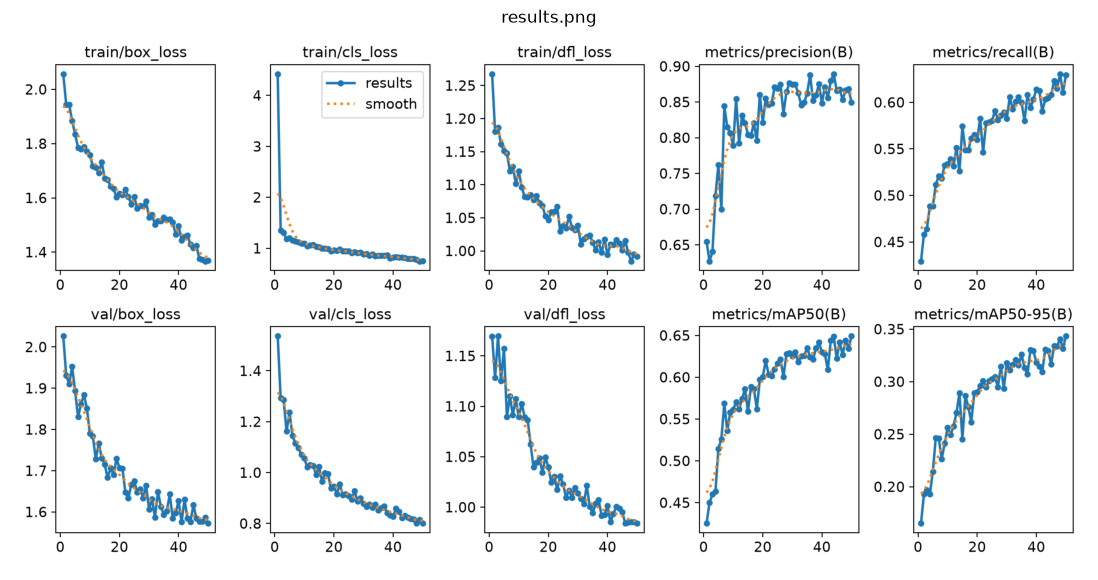

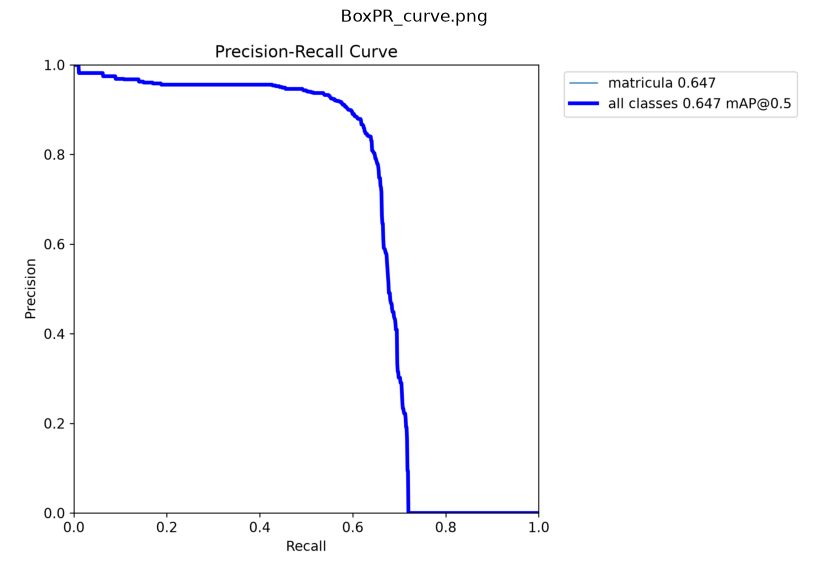

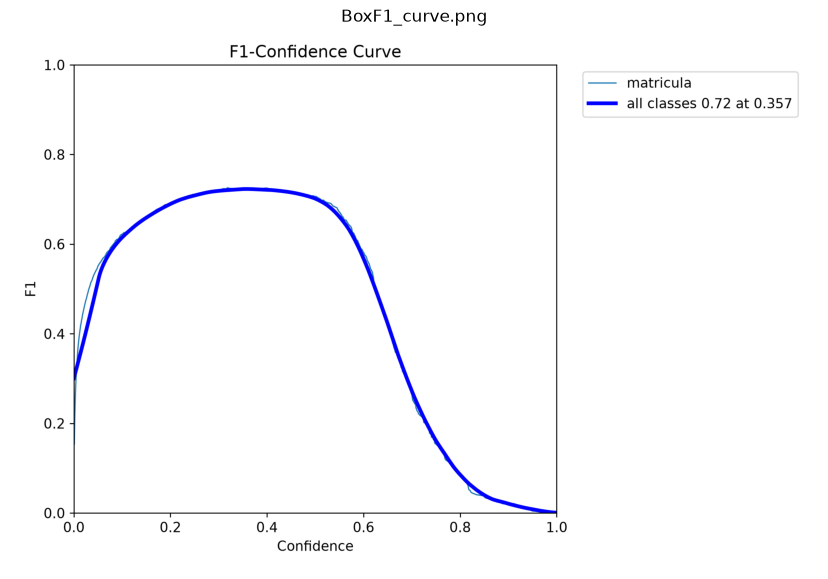

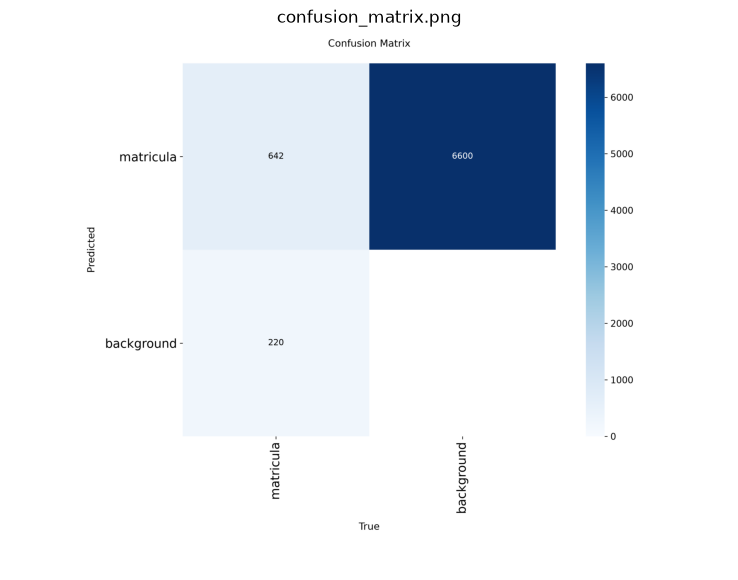

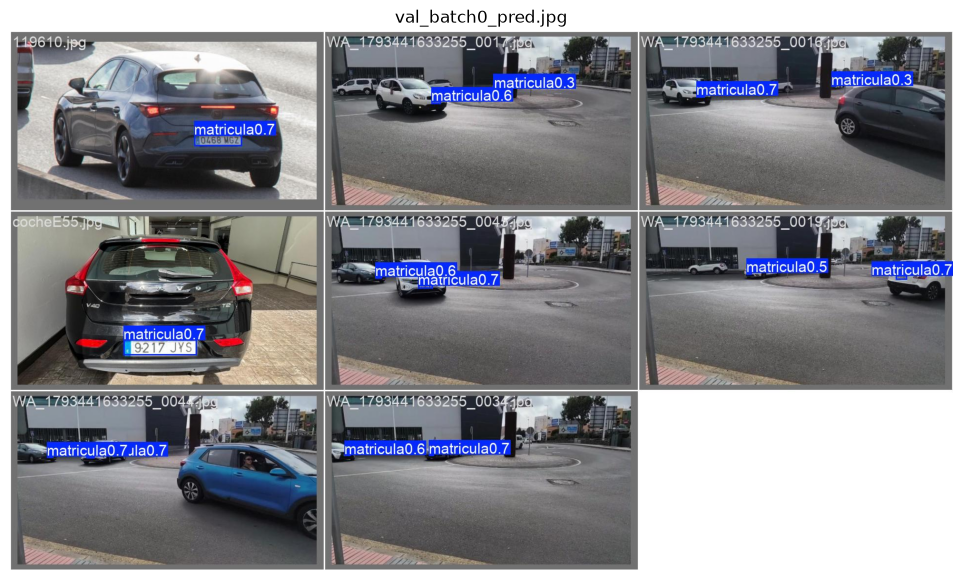

In [11]:
CARPETA_TRAIN = 'runs/modelos/runs/matriculas'

for nombre in ['results.png', 'BoxPR_curve.png', 'BoxF1_curve.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']:
    img = cv2.imread(os.path.join(CARPETA_TRAIN, nombre))
    plt.figure(figsize=(14, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(nombre)
    plt.axis('off')
    plt.show()

PASO 1.5: EVALUACIÓN SOBRE TEST

In [12]:
modelo_mat = YOLO(MODELO_MATRICULAS)
metricas = modelo_mat.val(data=DATASET_YAML, split='test', imgsz=640, batch=4, device=0)

print(f'Precisión : {metricas.box.mp:.3f}')
print(f'Recall    : {metricas.box.mr:.3f}')
print(f'mAP50     : {metricas.box.map50:.3f}')
print(f'mAP50-95  : {metricas.box.map:.3f}')

Ultralytics 8.4.183  Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce GTX 1050, 3072MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.6±0.4 ms, read: 67.8±78.4 MB/s, size: 1238.2 KB)
val: Scanning C:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\dataset\test\labels... 478 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 478/478 45.1it/s 10.6s0.4s
val: C:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\dataset\test\images\20261031_174251.jpg: corrupt JPEG restored and saved
val: C:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\dataset\test\images\20261031_190521.jpg: corrupt JPEG restored and saved
val: C:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\dataset\test\images\20261031_190654.jpg: corrupt JPEG restored and saved
val: C:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\dataset\test\images\20261031_190858.jpg: corrupt JPEG restored and saved
val: C:\Users\Usuario\Desktop\escitorio2\V

PASO 1.6: PRUEBA DEL DETECTOR SOBRE EL VÍDEO

Frames analizados: 566 de 2832
Frames con al menos una matrícula: 316


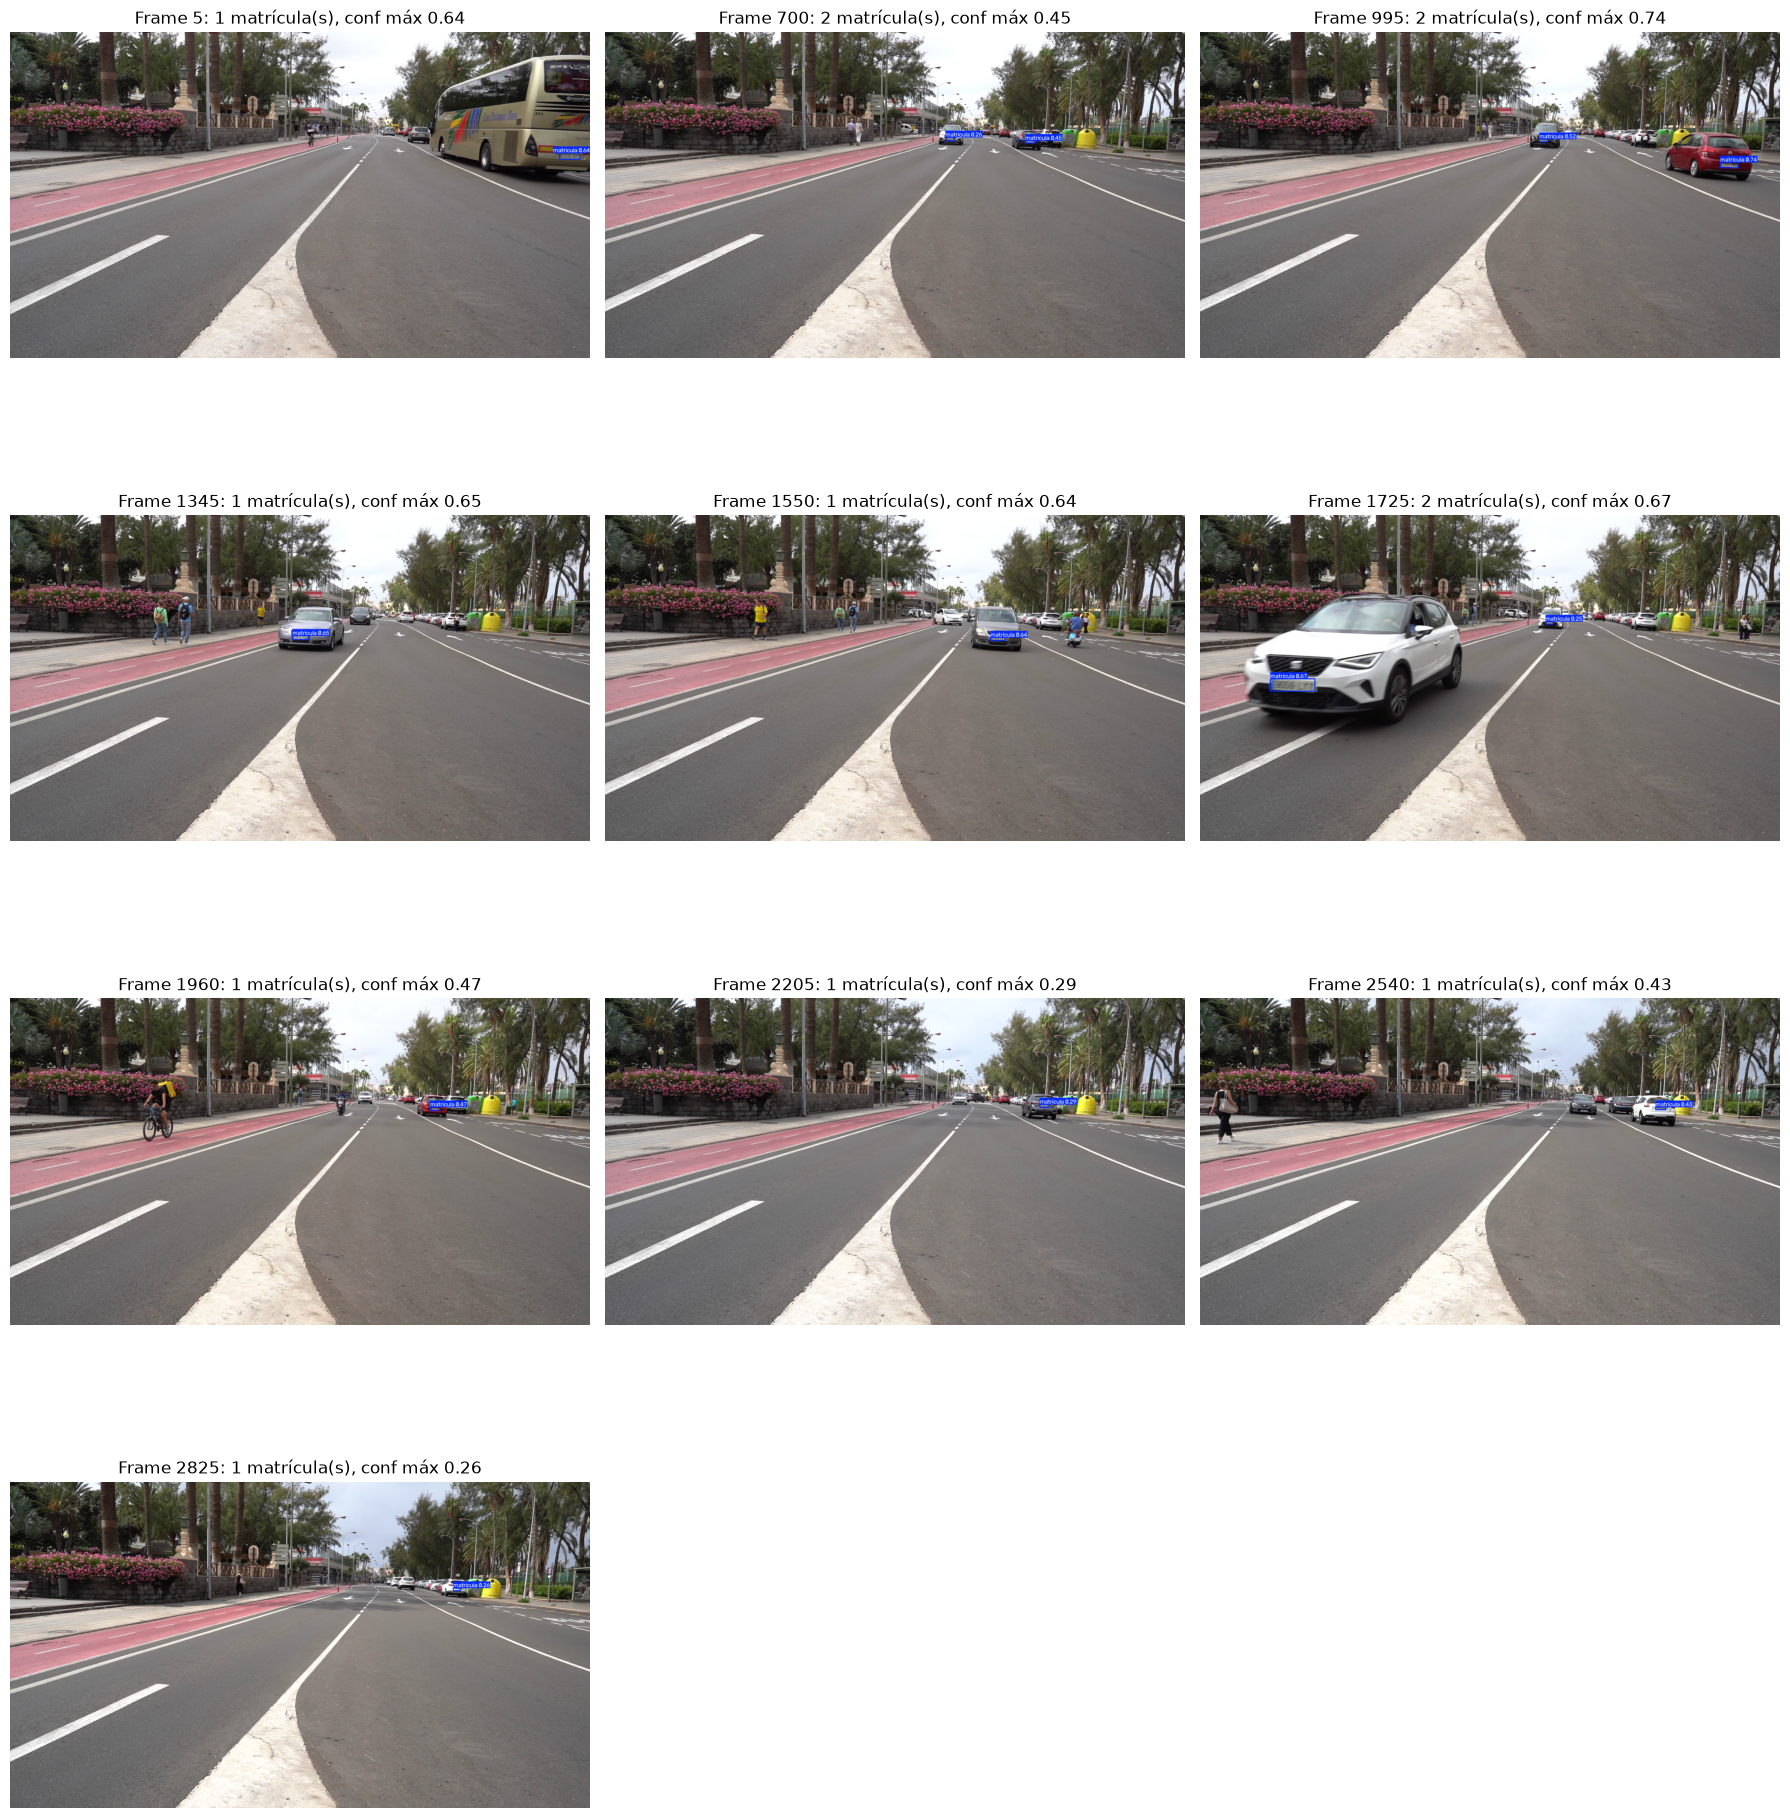

In [18]:
modelo_mat = YOLO(MODELO_MATRICULAS)

PASO = 5          # analiza 1 de cada 5 frames (más rápido); pon 1 para analizarlos todos
N_MOSTRAR = 10     # cuántos frames con detecciones enseñar
CONF = 0.25

cap = cv2.VideoCapture(VIDEO_PATH)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

frames_con_matricula = []   # (nº de frame, imagen con las cajas dibujadas, nº de matrículas, confianza máxima)
idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    if idx % PASO == 0:
        res = modelo_mat.predict(frame, conf=CONF, device=0, verbose=False)[0]
        if len(res.boxes) > 0:
            frames_con_matricula.append((idx, res.plot(line_width=2), len(res.boxes), float(res.boxes.conf.max())))
    idx += 1
cap.release()

print(f'Frames analizados: {total_frames // PASO} de {total_frames}')
print(f'Frames con al menos una matrícula: {len(frames_con_matricula)}')

# Elegir N_MOSTRAR frames repartidos entre los que tienen detección
if frames_con_matricula:
    elegidos = np.linspace(0, len(frames_con_matricula) - 1, min(N_MOSTRAR, len(frames_con_matricula)), dtype=int)
    filas = int(np.ceil(len(elegidos) / 3))
    plt.figure(figsize=(18, 5 * filas))
    for i, k in enumerate(elegidos):
        n_frame, img, n_mat, conf_max = frames_con_matricula[k]
        plt.subplot(filas, 3, i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f'Frame {n_frame}: {n_mat} matrícula(s), conf máx {conf_max:.2f}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

---
# PARTE 2: PIPELINE DE DETECCIÓN Y SEGUIMIENTO

Para cada fotograma del vídeo:

1. **YOLO11n + BoT-SORT** detecta y sigue personas y vehículos, asignando a cada objeto un identificador que se mantiene entre fotogramas.
2. Para cada vehículo se **recorta su caja** y se busca la matrícula con el detector entrenado en la Parte 1. Al recortar, la matrícula ocupa más píxeles que en el fotograma completo y se detecta mejor.
3. Las coordenadas de la matrícula se pasan del recorte al fotograma sumando la esquina del vehículo.
4. Se dibuja todo, se escribe el fotograma en el vídeo de salida y una fila por objeto en el CSV.

PASO 2.1: CARGAR MODELOS Y PARÁMETROS

In [19]:
import time
import torch
from collections import Counter, defaultdict

DEVICE = 0 if torch.cuda.is_available() else 'cpu'

modelo_general = YOLO(MODELO_GENERAL)      # COCO: personas y vehículos
modelo_mat     = YOLO(MODELO_MATRICULAS)   # detector de matrículas entrenado en la Parte 1

VEHICULOS        = {2, 3, 5, 7}     # coche, moto, autobús, camión
CONF_OBJETOS     = 0.30   # confianza mínima de personas y vehículos
CONF_MATRICULA   = 0.25   # confianza mínima de matrícula (el recall es el punto débil, mejor ser permisivo)
TAM_MIN_VEHICULO = 60     # ancho mínimo (px) del vehículo para buscar matrícula: en los lejanos no se distingue
MARGEN           = 0.05   # margen extra alrededor del vehículo al recortar
MIN_FRAMES_TRACK = 5      # un objeto debe aparecer al menos en 5 fotogramas para contarlo (filtra ruido)
ANCHO_SALIDA     = 1280   # el vídeo de salida se reduce a 1280x720 para que ocupe menos
MAX_FRAMES       = None   # None = vídeo completo; poner p.ej. 200 para pruebas rápidas

# Colores (BGR) por clase
COLORES = {0: (255, 140, 0), 1: (0, 200, 255), 2: (0, 220, 0), 3: (255, 0, 255), 5: (0, 140, 255), 7: (255, 255, 0)}
COLOR_MATRICULA = (0, 0, 255)

print('Dispositivo:', DEVICE)
print('Clases seguidas:', CLASES_INTERES)

Dispositivo: 0
Clases seguidas: {0: 'persona', 1: 'bicicleta', 2: 'coche', 3: 'moto', 5: 'autobus', 7: 'camion'}


PASO 2.2: FUNCIONES AUXILIARES

In [20]:
def detectar_matriculas(frame, cajas_vehiculos):
    """Busca la matrícula dentro de cada vehículo.

    Todos los recortes se pasan al detector de una vez (en lote), que es más rápido que uno a uno.
    Devuelve una lista paralela a cajas_vehiculos con (conf, mx1, my1, mx2, my2) en coordenadas
    del fotograma, o None si no se encuentra matrícula.
    """
    alto, ancho = frame.shape[:2]
    resultado = [None] * len(cajas_vehiculos)
    recortes, origenes = [], []
    for i, (x1, y1, x2, y2) in enumerate(cajas_vehiculos):
        if x2 - x1 < TAM_MIN_VEHICULO:
            continue
        mx, my = int((x2 - x1) * MARGEN), int((y2 - y1) * MARGEN)
        cx1, cy1 = max(0, x1 - mx), max(0, y1 - my)
        cx2, cy2 = min(ancho, x2 + mx), min(alto, y2 + my)
        recortes.append(frame[cy1:cy2, cx1:cx2])
        origenes.append((i, cx1, cy1))

    if not recortes:
        return resultado

    predicciones = modelo_mat.predict(recortes, conf=CONF_MATRICULA, device=DEVICE, verbose=False)
    for (i, ox, oy), pred in zip(origenes, predicciones):
        if len(pred.boxes) == 0:
            continue
        k = int(pred.boxes.conf.argmax())                      # la matrícula más segura del vehículo
        bx1, by1, bx2, by2 = pred.boxes.xyxy[k].cpu().numpy().astype(int)
        resultado[i] = (float(pred.boxes.conf[k]), ox + bx1, oy + by1, ox + bx2, oy + by2)  # recorte -> frame
    return resultado


def texto_con_fondo(img, texto, x, y, color, escala=0.6, grosor=2):
    """Escribe un texto con un rectángulo de fondo para que se lea sobre cualquier imagen."""
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, grosor)
    y = max(y, th + base + 2)
    cv2.rectangle(img, (x, y - th - base - 2), (x + tw + 4, y + 2), color, -1)
    cv2.putText(img, texto, (x + 2, y - base), cv2.FONT_HERSHEY_SIMPLEX, escala, (0, 0, 0), grosor, cv2.LINE_AA)


def dibujar_resultados(frame, detecciones, conteo):
    """Dibuja cajas, clase, ID de tracking y matrícula, y un panel con el conteo acumulado."""
    vis = frame.copy()
    for d in detecciones:
        x1, y1, x2, y2 = d['caja']
        color = COLORES[d['clase']]
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, 3)
        texto_con_fondo(vis, f"{CLASES_INTERES[d['clase']]} #{d['id']} {d['conf']:.2f}", x1, y1 - 4, color)
        if d['matricula'] is not None:
            mconf, mx1, my1, mx2, my2 = d['matricula']
            cv2.rectangle(vis, (mx1, my1), (mx2, my2), COLOR_MATRICULA, 3)
            texto_con_fondo(vis, f'matricula {mconf:.2f}', mx1, my2 + 24, (80, 80, 255), escala=0.55)

    # Panel de conteo (objetos únicos vistos hasta ahora)
    lineas = [f'{CLASES_INTERES[c]}: {n}' for c, n in sorted(conteo.items())]
    alto_panel = 40 + 32 * len(lineas)
    capa = vis.copy()
    cv2.rectangle(capa, (10, 10), (330, 10 + alto_panel), (0, 0, 0), -1)
    vis = cv2.addWeighted(capa, 0.55, vis, 0.45, 0)
    cv2.putText(vis, 'Total detectados', (22, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
    for k, linea in enumerate(lineas):
        cv2.putText(vis, linea, (22, 76 + 32 * k), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 2, cv2.LINE_AA)
    return vis


def conteo_actual(tracks):
    """Objetos únicos por clase (clase mayoritaria del track, solo tracks con suficientes fotogramas)."""
    conteo = Counter()
    for t in tracks.values():
        if t['frames'] >= MIN_FRAMES_TRACK:
            conteo[t['clases'].most_common(1)[0][0]] += 1
    return conteo

PASO 2.3: BUCLE PRINCIPAL (tracking + matrículas + vídeo + CSV)

In [ ]:
CABECERA = ['fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking', 'x1', 'y1', 'x2', 'y2',
            'matricula_en_su_caso', 'confianza_matricula', 'mx1', 'my1', 'mx2', 'my2', 'texto_matricula']

modelo_general = YOLO(MODELO_GENERAL)   # se recarga para que el tracker empiece de cero en cada ejecución

cap = cv2.VideoCapture(VIDEO_PATH)
fps   = cap.get(cv2.CAP_PROP_FPS)
ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
alto  = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
tam_salida = (ANCHO_SALIDA, int(alto * ANCHO_SALIDA / ancho))
writer = cv2.VideoWriter(SALIDA_VIDEO, cv2.VideoWriter_fourcc(*'mp4v'), fps, tam_salida)
print(f'Vídeo: {ancho}x{alto}, {fps:.0f} FPS, {total} fotogramas -> salida {tam_salida[0]}x{tam_salida[1]}')

# Información acumulada de cada objeto seguido
tracks = defaultdict(lambda: {'clases': Counter(), 'frames': 0, 'primero': None, 'ultimo': None,
                              'matriculas': 0, 'mejor_conf_matricula': 0.0})

n_frame, filas_csv, t0 = 0, 0, time.time()
with open(SALIDA_CSV, 'w', newline='', encoding='utf-8') as f_csv:
    escritor = csv.writer(f_csv)
    escritor.writerow(CABECERA)

    while True:
        ok, frame = cap.read()
        if not ok or (MAX_FRAMES is not None and n_frame >= MAX_FRAMES):
            break

        res = modelo_general.track(frame, persist=True, classes=list(CLASES_INTERES), conf=CONF_OBJETOS,
                                   device=DEVICE, verbose=False)[0]
        detecciones = []
        if res.boxes.id is not None:
            cajas  = res.boxes.xyxy.cpu().numpy().astype(int)
            clases = res.boxes.cls.cpu().numpy().astype(int)
            confs  = res.boxes.conf.cpu().numpy()
            ids    = res.boxes.id.cpu().numpy().astype(int)

            # Matrículas solo dentro de los vehículos
            idx_vehiculos = [i for i, c in enumerate(clases) if c in VEHICULOS]
            matriculas = dict(zip(idx_vehiculos, detectar_matriculas(frame, [cajas[i] for i in idx_vehiculos])))

            for i in range(len(cajas)):
                x1, y1, x2, y2 = cajas[i]
                clase, tid, mat = int(clases[i]), int(ids[i]), matriculas.get(i)
                detecciones.append({'clase': clase, 'conf': float(confs[i]), 'id': tid,
                                    'caja': (x1, y1, x2, y2), 'matricula': mat})

                # Acumular datos del track (clase, nº de fotogramas, trayectoria, matrículas)
                t = tracks[tid]
                t['clases'][clase] += 1
                t['frames'] += 1
                centro = ((x1 + x2) / 2, (y1 + y2) / 2)
                t['primero'] = t['primero'] or (n_frame, centro)
                t['ultimo'] = (n_frame, centro)
                if mat is not None:
                    t['matriculas'] += 1
                    t['mejor_conf_matricula'] = max(t['mejor_conf_matricula'], mat[0])

                # Fila del CSV (texto_matricula se rellena en la Tarea 2 con el OCR)
                if mat is not None:
                    mconf, mx1, my1, mx2, my2 = mat
                    datos_mat = ['si', round(mconf, 3), mx1, my1, mx2, my2, '']
                else:
                    datos_mat = ['no', '', '', '', '', '', '']
                escritor.writerow([n_frame, CLASES_INTERES[clase], round(float(confs[i]), 3), tid,
                                   x1, y1, x2, y2] + datos_mat)
                filas_csv += 1

        vis = dibujar_resultados(frame, detecciones, conteo_actual(tracks))
        writer.write(cv2.resize(vis, tam_salida))

        n_frame += 1
        if n_frame % 250 == 0:
            print(f'  {n_frame}/{total} fotogramas ({n_frame / (time.time() - t0):.1f} FPS)')

cap.release()
writer.release()
duracion = time.time() - t0
print(f'Procesados {n_frame} fotogramas en {duracion:.0f} s ({n_frame / duracion:.1f} FPS)')
print(f'Filas escritas en el CSV: {filas_csv}')
print('Vídeo:', os.path.abspath(SALIDA_VIDEO))
print('CSV  :', os.path.abspath(SALIDA_CSV))

Vídeo: 1920x1080, 25 FPS, 2832 fotogramas -> salida 1280x720
  250/2832 fotogramas (4.7 FPS)
  500/2832 fotogramas (4.9 FPS)
  750/2832 fotogramas (5.0 FPS)
  1000/2832 fotogramas (5.0 FPS)
  1250/2832 fotogramas (5.0 FPS)
  1500/2832 fotogramas (4.8 FPS)
  1750/2832 fotogramas (4.6 FPS)
  2000/2832 fotogramas (4.6 FPS)
  2250/2832 fotogramas (4.5 FPS)
  2500/2832 fotogramas (4.6 FPS)
  2750/2832 fotogramas (4.7 FPS)
Procesados 2832 fotogramas en 596 s (4.7 FPS)
Filas escritas en el CSV: 9064
Vídeo: c:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\resultados\resultado.mp4
CSV  : c:\Users\Usuario\Desktop\escitorio2\VC\VC\PRACTICA_4\resultados\resultado.csv


PASO 2.4: CONTEO DE OBJETOS ÚNICOS POR CLASE Y FLUJO POR DIRECCIÓN

* Se cuentan **identificadores únicos**, no detecciones: un coche aparece en cientos de fotogramas pero tiene un solo ID.
* La clase de cada objeto es la **mayoritaria** a lo largo de su track (a veces un mismo coche se detecta en algún fotograma como camión).
* Se descartan los tracks de menos de `MIN_FRAMES_TRACK` fotogramas, que suelen ser detecciones espurias.
* **Flujo (extra):** con la posición del centro del objeto en su primer y último fotograma se calcula hacia dónde se mueve.

Tracks totales: 59 | válidos (>= 5 fotogramas): 59

OBJETOS ÚNICOS POR CLASE
  persona   : 16
  bicicleta : 1
  coche     : 40
  moto      : 1
  autobus   : 1
  camion    : 0
  TOTAL     : 59

Vehículos con matrícula detectada en algún fotograma: 31 de 42

FLUJO POR DIRECCIÓN
clase       hacia la izquierda    hacia la derecha     hacia la cámara          alejándose              parado
autobus                      1                   0                   0                   0                   0
coche                       29                   7                   0                   0                   4
persona                      3                  11                   0                   0                   2
bicicleta                    1                   0                   0                   0                   0
moto                         1                   0                   0                   0                   0


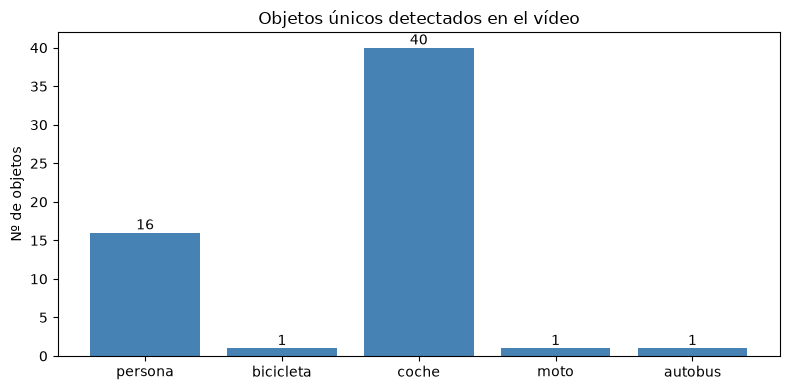

In [22]:
def direccion(track, umbral_px=40):
    """Dirección del movimiento entre el primer y el último fotograma en que se ve el objeto."""
    (_, (xa, ya)), (_, (xb, yb)) = track['primero'], track['ultimo']
    dx, dy = xb - xa, yb - ya
    if max(abs(dx), abs(dy)) < umbral_px:
        return 'parado'
    if abs(dx) >= abs(dy):
        return 'hacia la derecha' if dx > 0 else 'hacia la izquierda'
    return 'hacia la cámara' if dy > 0 else 'alejándose'


validos = {tid: t for tid, t in tracks.items() if t['frames'] >= MIN_FRAMES_TRACK}
clase_track = {tid: t['clases'].most_common(1)[0][0] for tid, t in validos.items()}
conteo = Counter(CLASES_INTERES[c] for c in clase_track.values())

print(f'Tracks totales: {len(tracks)} | válidos (>= {MIN_FRAMES_TRACK} fotogramas): {len(validos)}\n')
print('OBJETOS ÚNICOS POR CLASE')
for nombre in CLASES_INTERES.values():
    print(f'  {nombre:10s}: {conteo.get(nombre, 0)}')
print(f'  {"TOTAL":10s}: {sum(conteo.values())}')

vehiculos_validos = [tid for tid, c in clase_track.items() if c in VEHICULOS]
con_matricula = [tid for tid in vehiculos_validos if validos[tid]['matriculas'] > 0]
print(f'\nVehículos con matrícula detectada en algún fotograma: {len(con_matricula)} de {len(vehiculos_validos)}')

# Flujo por dirección
flujo = defaultdict(Counter)
for tid, t in validos.items():
    flujo[CLASES_INTERES[clase_track[tid]]][direccion(t)] += 1

direcciones = ['hacia la izquierda', 'hacia la derecha', 'hacia la cámara', 'alejándose', 'parado']
print('\nFLUJO POR DIRECCIÓN')
print(f'{"clase":10s}' + ''.join(f'{d:>20s}' for d in direcciones))
for nombre, c in flujo.items():
    print(f'{nombre:10s}' + ''.join(f'{c.get(d, 0):>20d}' for d in direcciones))

# Gráfica de conteo
plt.figure(figsize=(8, 4))
nombres = [n for n in CLASES_INTERES.values() if conteo.get(n, 0) > 0]
barras = plt.bar(nombres, [conteo[n] for n in nombres], color='steelblue')
plt.bar_label(barras)
plt.title('Objetos únicos detectados en el vídeo')
plt.ylabel('Nº de objetos')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, 'conteo_clases.png'), dpi=120)
plt.show()

PASO 2.5: RESULTADOS

Filas del CSV: 9064 | fotogramas: 2832 | filas con matrícula: 1312


,fotograma,tipo_objeto,confianza,identificador_tracking,x1,y1,x2,y2,matricula_en_su_caso,confianza_matricula,mx1,my1,mx2,my2,texto_matricula
2,1,autobus,0.933,1,1402,57,1918,470,si,0.385,1884.0,409.0,1920.0,426.0,NaN
4,2,autobus,0.936,1,1393,65,1918,466,si,0.621,1867.0,407.0,1920.0,425.0,NaN
6,3,autobus,0.900,1,1388,67,1918,467,si,0.631,1851.0,404.0,1918.0,425.0,NaN
8,4,autobus,0.930,1,1391,73,1918,464,si,0.691,1837.0,403.0,1903.0,423.0,NaN
10,5,autobus,0.935,1,1394,76,1918,461,si,0.419,1821.0,402.0,1889.0,421.0,NaN
12,6,autobus,0.934,1,1391,79,1918,461,si,0.731,1807.0,400.0,1875.0,420.0,NaN
14,7,autobus,0.935,1,1388,84,1918,458,si,0.688,1794.0,399.0,1860.0,417.0,NaN
16,8,autobus,0.937,1,1385,88,1918,457,si,0.731,1781.0,398.0,1845.0,416.0,NaN
18,9,autobus,0.941,1,1383,92,1918,457,si,0.701,1769.0,397.0,1831.0,415.0,NaN
20,10,autobus,0.937,1,1382,95,1918,456,si,0.679,1756.0,395.0,1819.0,414.0,NaN


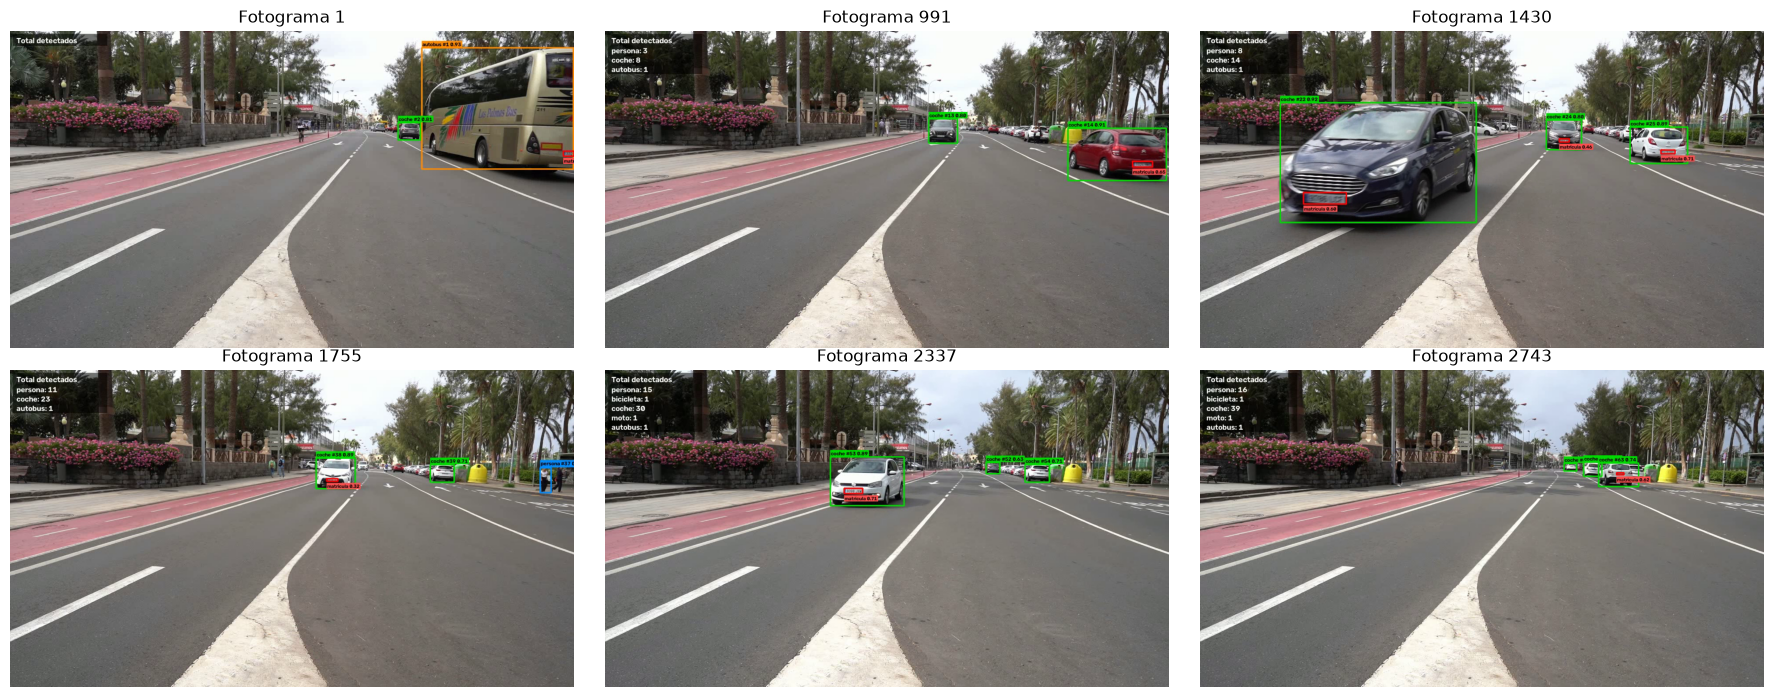

In [23]:
import pandas as pd

df = pd.read_csv(SALIDA_CSV)
print(f'Filas del CSV: {len(df)} | fotogramas: {df.fotograma.nunique()} | filas con matrícula: {(df.matricula_en_su_caso == "si").sum()}')
display(df[df.matricula_en_su_caso == 'si'].head(10))

# Algunos fotogramas del vídeo resultado con matrícula detectada
fotogramas = sorted(df.loc[df.matricula_en_su_caso == 'si', 'fotograma'].unique())
elegidos = [fotogramas[i] for i in np.linspace(0, len(fotogramas) - 1, min(6, len(fotogramas)), dtype=int)]

cap = cv2.VideoCapture(SALIDA_VIDEO)
plt.figure(figsize=(18, 7))
for k, n in enumerate(elegidos):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(n))
    ok, img = cap.read()
    if not ok:
        continue
    cv2.imwrite(os.path.join(CARPETA_RESULTADOS, f'frame_{n}.jpg'), img)   # para el README
    plt.subplot(2, 3, k + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f'Fotograma {n}')
    plt.axis('off')
cap.release()
plt.tight_layout()
plt.show()